In [2]:

import numpy as np
import pandas as pd
import os
import rioxarray as rxr
from osgeo import gdal
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline, make_pipeline
import geopandas as gpd
import rasterio
from shapely.geometry import box
from shapely.geometry import Point
from rasterio.sample import sample_gen
import xgboost as xgb

from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from skopt import BayesSearchCV
from skopt.space import Integer, Real
import matplotlib as mpl
import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from rasterio.transform import from_origin
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import box
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import rioxarray as rxr

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'

c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [2]:
path = 'G:\ICESat-2\Discussion5_3\Validation_point_Morecambe.shp'
k = gpd.read_file(path)
k.columns

Index(['Refer_dem', 'B1_10_0', 'B2_10_0', 'B3_10_0', 'B4_10_0', 'B1_20_0',
       'B2_20_0', 'B3_20_0', 'B4_20_0', 'B1_30_0',
       ...
       'B4_50_4', 'B1_60_4', 'B2_60_4', 'B3_60_4', 'B4_60_4', 'B1_70_4',
       'B2_70_4', 'B3_70_4', 'B4_70_4', 'geometry'],
      dtype='object', length=142)

In [3]:
def save_img(output_filename, reference_filename, array):
    
    reference = gdal.Open(reference_filename)
    
    # 获取地理变换参数和坐标系
    geo_transform = reference.GetGeoTransform()
    projection = reference.GetProjection()

    # 获取矩阵尺寸
    rows, cols = array.shape

    # 创建新的 TIFF 数据集
    driver = gdal.GetDriverByName('GTiff')
    out_data = driver.Create(output_filename, cols, rows, 1, gdal.GDT_Float32)

    # 设置地理变换和坐标系
    out_data.SetGeoTransform(geo_transform)
    out_data.SetProjection(projection)
    

    # 写入数据
    out_data.GetRasterBand(1).WriteArray(array)

    # 保存并关闭文件
    out_data.FlushCache()
    out_data = None
    
def load_refer_ICESat_point(FB_raster, icesat_csv_path, output_point, output_raw_point):
    
    df = pd.read_csv(icesat_csv_path)
    lon, lat = 'mean_lon', 'mean_lat'
    LULC_path = "E:/Downloads/tes/UK_LULC.tif"
    geometry = [Point(xy) for xy in zip(df[lon], df[lat])]
    gdf = gpd.GeoDataFrame(df, geometry=geometry)
    gdf.set_crs(epsg=4326, inplace=True)
    points = gdf
    
    with rasterio.open(FB_raster) as src:
        
        if points.crs != src.crs:
            points = points.to_crs(src.crs)
        coords = [(point.x, point.y) for point in points.geometry]
        values = list(src.sample(coords))
        
        band_count = src.count
        for band in range(band_count):
            points[f"b{band+1}_FB6"] = [v[band] for v in values]
            
    with rasterio.open(LULC_path) as src:

        if points.crs != src.crs:
            points = points.to_crs(src.crs)
        coords = [(point.x, point.y) for point in points.geometry]
        values = list(src.sample(coords))

        band_count = src.count
        points['LULC'] = [v[0] for v in values] 
     
    icesat_mask = (points['OH'] < 5) & (points['b6_FB6'] > 0) #& ((points['LULC'] == 200) | (points['LULC'] == 80))
    data = points[icesat_mask]
    
    points.to_file(output_raw_point)
    data.to_file(output_point)
    
    return data

def optimize_random_forest(x_train, y_train,  n_iter=30, cv=3):

    # if feature_columns is None:
    #     raise ValueError("feature_columns must be provided.")

    classifier = RandomForestRegressor(random_state=42)

    search_space = {
        'n_estimators': Integer(50, 500),
        'max_depth': Integer(3, 20),
        'min_samples_split': Integer(2, 20),
        'min_samples_leaf': Integer(1, 20),
        'max_features': Real(0.1, 1.0)
    }

    opt = BayesSearchCV(
        estimator=classifier,
        search_spaces=search_space,
        n_iter=n_iter,
        cv=cv,
        scoring='neg_mean_squared_error',
        random_state=42,
        n_jobs=-1
    )

    opt.fit(x_train, y_train)

    best_params = opt.best_params_
    print('Best hyperparameters:', best_params)
    print('Best score (negative MSE):', opt.best_score_)

    # 使用最优参数重新训练模型
    final_model = RandomForestRegressor(**best_params, random_state=42)
    # final_model.fit(x_train, y_train)

    return best_params, final_model


In [ ]:
region = 'Region4'
location = 'Morecambe'
# year_list = [2019, 2020, 2021, 2022, 2023, 2024]
year = 2023
num = [10, 20, 30, 40, 50 ,60, 70, 76]
# num = [76]
No = [1, 2, 3, 4, 5]

method = 'RF'



LULC_path = "E:/Downloads/tes/UK_LULC.tif"
LULC = rxr.open_rasterio(LULC_path, masked=True).squeeze()

band_list = [1, 2, 3]
# target_band, target_id = ['b1_FB6'], [0]
for band in band_list:
    
    target_band_list, target_id_list = ['b1_FB6','b2_FB6','b3_FB6','b4_FB6'], [0, 1, 2, 3]
    target_band, target_id = target_band_list[:band], target_id_list[:band]
    
    for j in range(len(No)):

        for i in range(len(num)):
            
            FB_raster_path = f"G:\ICESat-2\Discussion51_new\Input_data\{location}_{year}_FB6_new9_{num[i]}_{No[j]}.tif"
            ICESAT_csv_path = f'G:\ICESat-2\{region}\{region}_{location}\A_{location}_30m_{year}_new10.csv'
            output_path = f'G:\ICESat-2\Discussion51_new\Retrieved_DEM\Morecambe\{location}_{year}_{band}_{method}_FB6_new9_{num[i]}_{No[j]}.tif'

            output_raw_point = f'G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_raw_new10.shp'
            output_point = f'G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.shp'
            data = load_refer_ICESat_point(FB_raster_path, ICESAT_csv_path, output_point, output_raw_point) 
            y_train = data['OH'].values
            x_train = data[target_band].values
            
            best_params, classifier = optimize_random_forest(x_train, y_train)
            classifier.fit(x_train, y_train)

            if not os.path.exists(FB_raster_path):
                print(FB_raster_path, 'is not exist!')
                break

            raster = rxr.open_rasterio(FB_raster_path).values
            raster = np.nan_to_num(raster, nan=0)
            selected_raster = raster[target_id, :, :]

            if len(selected_raster.shape) != 3:
                row, col = selected_raster.shape
                selected_raster = selected_raster.reshape(1, row, col)
            else: 
                bands, row, col = selected_raster.shape

            print('selected_raster.shape', selected_raster.shape)

            k = 0
            result = np.array([[]])
            for i in range(row):
                    
                x_train = np.transpose(selected_raster[:, i, :])
                if method == 'RF':
                    y_pred = classifier.predict(x_train)
                elif method == 'Linear':
                    y_pred = np.polyval(classifier, x_train)
                else:
                    y_pred = np.polyval(classifier, x_train)
                    
                result = np.append(result, y_pred)
                    
                if i%(int(row/5)) == 0:
                        
                    print(k*20 , '%_ is done')
                    k = k+1
                
            result = result.reshape(row, col)
            print(result.shape, type(result))
                # tf_mask = raster[6,:,:].flatten()
                # result[tf_mask == 0] = 0
                # result_ = result.reshape(row, col)
            tf_mask = raster[5,:,:]#.flatten()
                # Freq_s2 = raster[5,:,:]#.flatten()
                
            z = rxr.open_rasterio(FB_raster_path, masked=True).squeeze() 
            LULC_aligned = LULC.rio.reproject_match(z)
                
                #result[(tf_mask == 0) | ((LULC_aligned != 200) & (LULC_aligned != 80))] = 0
            result[(tf_mask == 0)] = 0       

            save_img(output_path, FB_raster_path, result)
            print(f'{location}_{year} is output to {output_path}')

In [5]:
ICESat_path = 'G:\ICESat-2\Discussion5_2_new\A_Ribble1_30m_2022_new10.shp'
data = gpd.read_file(ICESat_path)
data.columns

Index(['Unnamed__0', 'distance', 'mean_heigh', 'mean_lon', 'mean_lat', 'OSGM',
       'OH', 'Strip_No', 'b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6', 'b5_FB6',
       'b6_FB6', 'b7_FB6', 'Refer', 'geometry'],
      dtype='object')

In [ ]:
region = 'Region1'
location = 'Thames'
# year_list = [2019, 2020, 2021, 2022, 2023, 2024]
year = 2022
num = [10, 20, 30, 40, 50 ,60, 70, 80, 90, 100]
No = [1, 2, 3, 4, 5]
# num = [79]
# No = [0]
# No = [5, 6, 7, 8, 9]
method = 'RF'
# target_band, target_id = ['b1_FB6','b2_FB6','b3_FB6','b4_FB6'], [0, 1, 2, 3]
band = 4
target_band_list, target_id_list = ['b1_FB6','b2_FB6','b3_FB6','b4_FB6'], [0, 1, 2, 3]
target_band, target_id = target_band_list[:band], target_id_list[:band]

# LULC_path = "E:/UK_LULC.tif"
# LULC = rxr.open_rasterio(LULC_path, masked=True).squeeze()
band_list = [1, 2, 3, 4]
# target_band, target_id = ['b1_FB6'], [0]
for band in band_list:

    target_band_list, target_id_list = ['b1_FB6','b2_FB6','b3_FB6','b4_FB6'], [0, 1, 2, 3]
    target_band, target_id = target_band_list[:band], target_id_list[:band]
    
    for j in range(len(No)):

        for i in range(len(num)):
            
            FB_raster_path = f"G:\ICESat-2\Discussion51_new\Input_data\Thames_new\Thames_{year}_FB6_new9_{num[i]}_{No[j]}.tif"
            ICESAT_csv_path = f'G:\ICESat-2\{region}\{region}_{location}\A_{location}_30m_{year}_new10.csv'
            output_path = f'G:\ICESat-2\Discussion51_new\Retrieved_DEM\Thames_new\{location}_{year}_{band}_{method}_FB6_new9_{num[i]}_{No[j]}.tif'

            output_raw_point = f'G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_raw_new10.shp'
            output_point = f'G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.shp'
            data = load_refer_ICESat_point(FB_raster_path, ICESAT_csv_path, output_point, output_raw_point) 
            y_train = data['OH'].values
            x_train = data[target_band].values
            
            best_params, classifier = optimize_random_forest(x_train, y_train)
            classifier.fit(x_train, y_train)

            if not os.path.exists(FB_raster_path):
                print(FB_raster_path, 'is not exist!')
                break

            raster = rxr.open_rasterio(FB_raster_path).values
            raster = np.nan_to_num(raster, nan=0)
            selected_raster = raster[target_id, :, :]

            if len(selected_raster.shape) != 3:
                row, col = selected_raster.shape
                selected_raster = selected_raster.reshape(1, row, col)
            else: 
                bands, row, col = selected_raster.shape

            print('selected_raster.shape', selected_raster.shape)

            k = 0
            result = np.array([[]])
            for i in range(row):
                    
                x_train = np.transpose(selected_raster[:, i, :])
                if method == 'RF':
                    y_pred = classifier.predict(x_train)
                elif method == 'Linear':
                    y_pred = np.polyval(classifier, x_train)
                else:
                    y_pred = np.polyval(classifier, x_train)
                    
                result = np.append(result, y_pred)
                    
                if i%(int(row/5)) == 0:
                        
                    print(k*20 , '%_ is done')
                    k = k+1
                
            result = result.reshape(row, col)
            print(result.shape, type(result))
                # tf_mask = raster[6,:,:].flatten()
                # result[tf_mask == 0] = 0
                # result_ = result.reshape(row, col)
            tf_mask = raster[5,:,:]#.flatten()
                # Freq_s2 = raster[5,:,:]#.flatten()
                
            z = rxr.open_rasterio(FB_raster_path, masked=True).squeeze() 
            LULC_aligned = LULC.rio.reproject_match(z)
                
                #result[(tf_mask == 0) | ((LULC_aligned != 200) & (LULC_aligned != 80))] = 0
            result[(tf_mask == 0)] = 0       

            save_img(output_path, FB_raster_path, result)
            print(f'{location}_{year} is output to {output_path}')

In [ ]:
region = 'Region4'
location = 'Morecambe'
# year_list = [2019, 2020, 2021, 2022, 2023, 2024]
year = 2023
num = [10, 20, 30, 40, 50 ,60, 70, 76]
No = [1, 2, 3, 4, 5]
# num = [79]
# No = [0]
# No = [5, 6, 7, 8, 9]
method = 'RF'
# target_band, target_id = ['b1_FB6','b2_FB6','b3_FB6','b4_FB6'], [0, 1, 2, 3]
band = 4
target_band_list, target_id_list = ['b1_FB6','b2_FB6','b3_FB6','b4_FB6'], [0, 1, 2, 3]
target_band, target_id = target_band_list[:band], target_id_list[:band]

# LULC_path = "E:/UK_LULC.tif"
# LULC = rxr.open_rasterio(LULC_path, masked=True).squeeze()
band_list = [1, 2, 3, 4]
# target_band, target_id = ['b1_FB6'], [0]
for band in band_list:

    target_band_list, target_id_list = ['b1_FB6','b2_FB6','b3_FB6','b4_FB6'], [0, 1, 2, 3]
    target_band, target_id = target_band_list[:band], target_id_list[:band]
    
    for j in range(len(No)):

        for i in range(len(num)):
            
            FB_raster_path = f"H:\ICESat-2\Discussion51_new\Input_data\Morecambe_new\Morecambe_{year}_FB6_new9_{num[i]}_{No[j]}.tif"
            # ICESAT_csv_path = f'G:\ICESat-2\{region}\{region}_{location}\A_{location}_30m_{year}_new10.csv'
            ICESAT_csv_path = f'H:\ICESat-2\Region4_map\Morecambe_map\A2023\A_Morecambe_30m_2023_new_refined.csv'
            output_path = f'H:\ICESat-2\Discussion51_new\Retrieved_DEM\Morecambe_new\{location}_{year}_{band}_{method}_FB6_new9_{num[i]}_{No[j]}_refined.tif'

            output_raw_point = f'H:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_raw_new10.shp'
            output_point = f'H:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10_refined.shp'
            data = load_refer_ICESat_point(FB_raster_path, ICESAT_csv_path, output_point, output_raw_point) 
            y_train = data['OH'].values
            x_train = data[target_band].values
            
            best_params, classifier = optimize_random_forest(x_train, y_train)
            classifier.fit(x_train, y_train)

            if not os.path.exists(FB_raster_path):
                print(FB_raster_path, 'is not exist!')
                break

            raster = rxr.open_rasterio(FB_raster_path).values
            raster = np.nan_to_num(raster, nan=0)
            selected_raster = raster[target_id, :, :]

            if len(selected_raster.shape) != 3:
                row, col = selected_raster.shape
                selected_raster = selected_raster.reshape(1, row, col)
            else: 
                bands, row, col = selected_raster.shape

            print('selected_raster.shape', selected_raster.shape)

            k = 0
            result = np.array([[]])
            for i in range(row):
                    
                x_train = np.transpose(selected_raster[:, i, :])
                if method == 'RF':
                    y_pred = classifier.predict(x_train)
                elif method == 'Linear':
                    y_pred = np.polyval(classifier, x_train)
                else:
                    y_pred = np.polyval(classifier, x_train)
                    
                result = np.append(result, y_pred)
                    
                if i%(int(row/5)) == 0:
                        
                    print(k*20 , '%_ is done')
                    k = k+1
                
            result = result.reshape(row, col)
            print(result.shape, type(result))
                # tf_mask = raster[6,:,:].flatten()
                # result[tf_mask == 0] = 0
                # result_ = result.reshape(row, col)
            tf_mask = raster[5,:,:]#.flatten()
                # Freq_s2 = raster[5,:,:]#.flatten()
                
            z = rxr.open_rasterio(FB_raster_path, masked=True).squeeze() 
            # LULC_aligned = LULC.rio.reproject_match(z)
                
                #result[(tf_mask == 0) | ((LULC_aligned != 200) & (LULC_aligned != 80))] = 0
            result[(tf_mask == 0)] = 0       

            save_img(output_path, FB_raster_path, result)
            print(f'{location}_{year} is output to {output_path}')

In [ ]:
region = 'Region4'
location = 'Ribble'
# year_list = [2019, 2020, 2021, 2022, 2023, 2024]
year = 2022
num = [10, 20, 30, 40, 50 ,60, 70, 80, 90, 98] #ribble 2020 
num = []
No = [1]

# num = [98]
# No = [1]

method = 'RF'

LULC_path = "E:/Downloads/tes/UK_LULC.tif"
LULC = rxr.open_rasterio(LULC_path, masked=True).squeeze()

band_list = [3, 4]
# target_band, target_id = ['b1_FB6'], [0]
for band in band_list:
    
    target_band_list, target_id_list = ['b1_FB6','b2_FB6','b3_FB6','b4_FB6'], [0, 1, 2, 3]
    target_band, target_id = target_band_list[:band], target_id_list[:band]
    
    for j in range(len(No)):

        for i in range(len(num)):
            
            FB_raster_path = f"G:\ICESat-2\Discussion51_new\Input_data\Ribble1/ribble_{year}_FB6_new9_{num[i]}_{No[j]}.tif"
            # ICESat_path = 'G:\ICESat-2\Discussion5_2_new\A_Ribble1_30m_2022_new10.shp'
            # data = gpd.read_file(ICESat_path)
            
            ICESAT_csv_path = f'G:\ICESat-2\{region}\{region}_{location}\A_{location}_30m_{year}_new10.csv'
            output_path = f'G:\ICESat-2\Discussion51_new\Retrieved_DEM\Ribble\{location}_{year}_{band}_{method}_FB6_new9_{num[i]}_{No[j]}.tif'

            output_raw_point = f'G:\ICESat-2\{region}_map\{location}1_map\A{year}\A_{location}1_30m_{year}_raw_new10.shp'
            output_point = f'G:\ICESat-2\{region}_map\{location}1_map\A{year}\A_{location}1_30m_{year}_new10.shp'
            data = load_refer_ICESat_point(FB_raster_path, ICESAT_csv_path, output_point, output_raw_point) 
            
            y_train = data['OH'].values
            x_train = data[target_band].values
            
            best_params, classifier = optimize_random_forest(x_train, y_train)
            classifier.fit(x_train, y_train)

            if not os.path.exists(FB_raster_path):
                print(FB_raster_path, 'is not exist!')
                break

            raster = rxr.open_rasterio(FB_raster_path).values
            raster = np.nan_to_num(raster, nan=0)
            selected_raster = raster[target_id, :, :]

            if len(selected_raster.shape) != 3:
                row, col = selected_raster.shape
                selected_raster = selected_raster.reshape(1, row, col)
            else: 
                bands, row, col = selected_raster.shape

            print('selected_raster.shape', selected_raster.shape)

            k = 0
            result = np.array([[]])
            for i in range(row):
                    
                x_train = np.transpose(selected_raster[:, i, :])
                if method == 'RF':
                    y_pred = classifier.predict(x_train)
                elif method == 'Linear':
                    y_pred = np.polyval(classifier, x_train)
                else:
                    y_pred = np.polyval(classifier, x_train)
                    
                result = np.append(result, y_pred)
                    
                if i%(int(row/5)) == 0:
                        
                    print(k*20 , '%_ is done')
                    k = k+1
                
            result = result.reshape(row, col)
            print(result.shape, type(result))
                # tf_mask = raster[6,:,:].flatten()
                # result[tf_mask == 0] = 0
                # result_ = result.reshape(row, col)
            tf_mask = raster[5,:,:]#.flatten()
                # Freq_s2 = raster[5,:,:]#.flatten()
                
            z = rxr.open_rasterio(FB_raster_path, masked=True).squeeze() 
            LULC_aligned = LULC.rio.reproject_match(z)
                
                #result[(tf_mask == 0) | ((LULC_aligned != 200) & (LULC_aligned != 80))] = 0
            result[(tf_mask == 0)] = 0       

            save_img(output_path, FB_raster_path, result)
            print(f'{location}_{year} is output to {output_path}')

In [29]:
import geopandas as gpd

# 读取原始shp文件
path = r'G:\ICESat-2\Region4_map\Morecambe_map\A2023\Morecambe_2023_sample_points_final.shp'
z = gpd.read_file(path)

# 创建只包含Refer_dem字段和geometry的新GeoDataFrame
output = z[['Refer_dem', 'geometry']]

# 设置输出路径
output_path = r'G:\ICESat-2\Discussion51_new\Validation_point_Morecambe.shp'

# 写入shp文件
output.to_file(output_path)

In [ ]:

points_path = r'G:\ICESat-2\Discussion51_new\Ribble1_2022_sample_points_final.shp'
out_points_path = r'G:\ICESat-2\Discussion51_new\Validation_Ribble_2022.shp'
points = gpd.read_file(points_path)

# num = [10, 20, 30, 40, 50 ,60, 70, 76]
num = [10, 20, 30, 40, 50 ,60, 70, 80, 90, 98]
No = [ 2, 3, 4, 5]
# No = [1,5, 6, 7, 8, 9]
band_list = [1, 2, 3, 4]

for i in range(len(No)):
    
    for j in range(len(num)):
        
        for band in band_list:
            
            raster_path = f'G:\ICESat-2\Discussion51_new\Retrieved_DEM\Ribble\Ribble_2022_{band}_RF_FB6_new9_{num[j]}_{No[i]}.tif'

            with rasterio.open(raster_path) as src:
                
                raster_crs = src.crs
                if points.crs != raster_crs:
                    points = points.to_crs(raster_crs)
                
                coords = [(geom.x, geom.y) for geom in points.geometry]
                values = list(src.sample(coords))
                
                band_values = [val[0] for val in values]
                
                points[f'B{band}_{num[j]}_{No[i]}'] = band_values

points.to_file(out_points_path)

In [ ]:

points_path = r'H:\ICESat-2\Discussion51_new\Validation_point_Morecambe.shp'

out_points_path = r'H:\ICESat-2\Discussion51_new\Validation_point_Morecambe_new_r.shp'

# points_path = r'G:\ICESat-2\Discussion5_3\Validation_point_wash.shp'
# out_points_path = r'G:\ICESat-2\Discussion5_3\Validation_point_wash.shp'
points = gpd.read_file(points_path)

num = [10, 20, 30, 40, 50 ,60, 70, 76]
# num = [76]
# No = [0, 1, 2, 3, 4]
No = [1, 2, 3, 4, 5]
band_list = [1, 2, 3, 4]

for i in range(len(No)):
    
    for j in range(len(num)):
        
        for band in band_list:

            # raster_path = f'G:\ICESat-2\Discussion5_3\Retrieved_DEM\Morecambe\Morecambe_2023_{band}_RF_FB6_new9_{num[j]}_{No[i]}.tif'
            raster_path = f'H:\ICESat-2\Discussion51_new\Retrieved_DEM\Morecambe_new\Morecambe_2023_{band}_RF_FB6_new9_{num[j]}_{No[i]}_refined.tif'
            print(raster_path)
            with rasterio.open(raster_path) as src:
                
                raster_crs = src.crs
                if points.crs != raster_crs:
                    points = points.to_crs(raster_crs)
                
                coords = [(geom.x, geom.y) for geom in points.geometry]
                values = list(src.sample(coords))
                
                band_values = [val[0] for val in values]
                
                points[f'B{band}_{num[j]}_{No[i]}'] = band_values

points.to_file(out_points_path)




In [139]:
out_points_path = r'G:\ICESat-2\Discussion51_new\Validation_Ribble_2022.shp'
points = gpd.read_file(out_points_path)
points.columns
# points.shape

Index(['Refer_dem', 'retrieved_', 'SY', 'DEM_new9', 'DEM_ICESat', 'DEM_random',
       'ICE_SY', 'DEM98', 'B1_10_2', 'B2_10_2',
       ...
       'B4_80_5', 'B1_90_5', 'B2_90_5', 'B3_90_5', 'B4_90_5', 'B1_98_5',
       'B2_98_5', 'B3_98_5', 'B4_98_5', 'geometry'],
      dtype='object', length=169)

In [ ]:
z = points[points['B4_20_4']!=0]
z = z.dropna()

RMSE_4_list = []
MAD_4_list = []
num = [10, 20, 30, 40, 50 ,60, 70, 80, 90, 98]
No = [2, 3, 4, 5]
# No = [0, 1, 2, 3, 4]
# No = [5, 6, 7, 8, 9]

for i in range(len(num)):
    
    for j in range(len(No)):
        

        name2 = f'B4_{num[i]}_{No[j]}'

        x2 = z[name2]
        y = z['Refer_dem']
        y = np.array(y)
        x2 = np.array(x2)
        B4_MAE =  np.mean(np.abs(y-x2))
        B4_RMSE = np.sqrt(np.mean((y-x2)**2))
        
        RMSE_4_list.append(B4_RMSE)

        MAD_4_list.append(B4_MAE)

In [4]:
z = points[points['B3_20_4']!=0]
z = z.dropna()

RMSE_3_list = []
MAD_3_list = []
num = [10, 20, 30, 40, 50 ,60, 70, 80, 90, 98]
No = [2, 3, 4, 5]
# No = [5, 6, 7, 8, 9]

for i in range(len(num)):
    
    for j in range(len(No)):
        

        name2 = f'B3_{num[i]}_{No[j]}'

        x2 = z[name2]
        y = z['Refer_dem']
        y = np.array(y)
        x2 = np.array(x2)
        B4_MAE =  np.mean(np.abs(y-x2))
        B4_RMSE = np.sqrt(np.mean((y-x2)**2))
        
        RMSE_3_list.append(B4_RMSE)

        MAD_3_list.append(B4_MAE)

In [5]:
z = points[points['B2_20_4']!=0]
z = z.dropna()

RMSE_2_list = []
MAD_2_list = []
num = [10, 20, 30, 40, 50 ,60, 70, 80, 90, 98]
No = [2, 3, 4, 5]
# No = [5, 6, 7, 8, 9]

for i in range(len(num)):
    
    for j in range(len(No)):
        

        name2 = f'B2_{num[i]}_{No[j]}'

        x2 = z[name2]
        y = z['Refer_dem']
        y = np.array(y)
        x2 = np.array(x2)
        B4_MAE =  np.mean(np.abs(y-x2))
        B4_RMSE = np.sqrt(np.mean((y-x2)**2))
        
        RMSE_2_list.append(B4_RMSE)

        MAD_2_list.append(B4_MAE)

In [6]:
z = points[points['B4_20_2']!=0]
z = z.dropna()

RMSE_1_list = []
MAD_1_list = []
num = [10, 20, 30, 40, 50 ,60, 70, 80, 90, 98]
No = [2, 3, 4, 5]

for i in range(len(num)):
    
    for j in range(len(No)):
        

        name = f'B1_{num[i]}_{No[j]}'

        x1 =  z[name]
        y = z['Refer_dem']
        y = np.array(y)
        x1 = np.array(x1)
        B1_MAE =  np.mean(np.abs(y-x1))
        B1_RMSE = np.sqrt(np.mean((y-x1)**2))
        
        RMSE_1_list.append(B1_RMSE)

        MAD_1_list.append(B1_MAE)

In [11]:
mean_4_list

NameError: name 'mean_4_list' is not defined

In [6]:
import numpy as np

def compute_metrics(points, band_prefix, num_list, no_list, ref_col='Refer_dem'):
    """计算某个band下所有 num/no 组合的 RMSE 和 MAE"""
    # 过滤掉值为 0 的行
    z = points[points[f'{band_prefix}_20_4'] != 0].dropna()

    RMSE_list, MAD_list = [], []

    y = np.array(z[ref_col])

    for num in num_list:
        for no in no_list:
            col = f'{band_prefix}_{num}_{no}'
            x = np.array(z[col])

            mae = np.mean(np.abs(y - x))
            rmse = np.sqrt(np.mean((y - x) ** 2))

            RMSE_list.append(rmse)
            MAD_list.append(mae)

    return RMSE_list, MAD_list

In [15]:
import numpy as np

def compute_metrics(points, band_prefix, num_list, no_list, ref_col='Refer_dem'):
    """计算某个band下所有 num/no 组合的 RMSE 和 MAE"""
    # 过滤掉值为 0 的行
    z = points[points[f'{band_prefix}_20_4'] != 0].dropna()

    RMSE_list, MAD_list = [], []

    y = np.array(z[ref_col])

    for num in num_list:
        for no in no_list:
            col = f'{band_prefix}_{num}_{no}'
            x = np.array(z[col])

            mae = np.mean(np.abs(y - x))
            rmse = np.sqrt(np.mean((y - x) ** 2))

            RMSE_list.append(rmse)
            MAD_list.append(mae)

    return RMSE_list, MAD_list

# 参数设置
num = [10, 20, 30, 40, 50 ,60, 70, 80, 90, 98]
No = [2, 3, 4, 5]
points = gpd.read_file('G:\ICESat-2\Discussion51_new\Validation_Ribble_2022.shp')
# 四个 band
RMSE_1_list, MAD_1_list = compute_metrics(points, 'B1', num, No)
RMSE_2_list, MAD_2_list = compute_metrics(points, 'B2', num, No)
RMSE_3_list, MAD_3_list = compute_metrics(points, 'B3', num, No)
RMSE_4_list, MAD_4_list = compute_metrics(points, 'B4', num, No)

mean_1_list,mean_2_list,mean_3_list, mean_4_list = [], [], [], []
std_1_list, std_2_list, std_3_list, std_4_list = [], [], [], []
N  = len(No)

for i in range(1, len(num)+1):
    
    ii = i*N-N
    mean1 = np.array(RMSE_1_list[ii:ii+5]).mean()
    std1 = np.array(RMSE_1_list[ii:ii+5]).std()
    mean_1_list.append(mean1*100)
    std_1_list.append(std1*100)
    
    mean2 = np.array(RMSE_2_list[ii:ii+5]).mean()
    std2 = np.array(RMSE_2_list[ii:ii+5]).std()
    mean_2_list.append(mean2*100)
    std_2_list.append(std2*100)    
    
    mean3 = np.array(RMSE_3_list[ii:ii+5]).mean()
    std3 = np.array(RMSE_3_list[ii:ii+5]).std()
    mean_3_list.append(mean3*100)
    std_3_list.append(std3*100)
    
    mean4 = np.array(RMSE_4_list[ii:ii+5]).mean()
    std4 = np.array(RMSE_4_list[ii:ii+5]).std()  
    mean_4_list.append(mean4*100)
    std_4_list.append(std4*100) 

In [16]:
print(np.mean(mean_4_list))
np.mean(mean_1_list)

42.6646463792664


46.71347751598725

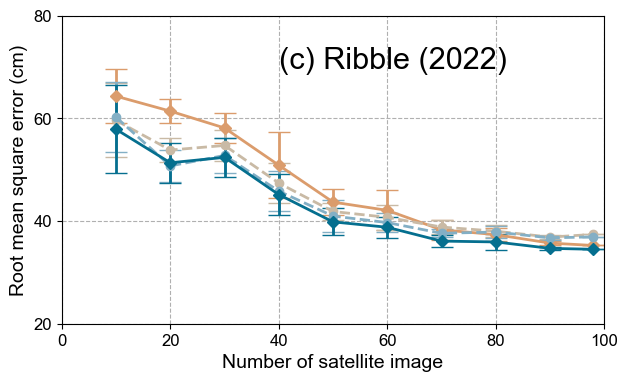

In [147]:
import numpy as np
import matplotlib.pyplot as plt

# 示例数据（可以替换为你的实际数据）
x = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 98])# 比如距离或序号，共30个点

fig, ax = plt.subplots(figsize=(7, 4))


color_list = ["#DB9C6C","#C9BAA5", "#83AFC5", "#056F8F"]
# color_list = ["#F0AD30","#34699A", "#58A0C8", "#113F67"]
# 绘制误差棒图（上下误差相等）
ax.errorbar(x, mean_1_list, yerr=std_1_list, fmt='D-', color=color_list[0], ecolor=color_list[0], capsize=8, elinewidth=2, linewidth=2)
ax.errorbar(x, mean_2_list, yerr=std_2_list, fmt='o--', color=color_list[1], ecolor=color_list[1], capsize=8, linewidth=2)
ax.errorbar(x, mean_3_list, yerr=std_3_list, fmt='o--', color=color_list[2], ecolor=color_list[2], capsize=8, elinewidth=2, linewidth=2)
ax.errorbar(x, mean_4_list, yerr=std_4_list, fmt='D-', color=color_list[3], ecolor=color_list[3], capsize=8, linewidth=2)

# 添加零线（更粗）
ax.axhline(y=0, linestyle='-', color='gray', linewidth=10, alpha=0.3)


ax.plot([], [], 'D-',  color=color_list[0], markeredgecolor=color_list[0], label='NAEF only')
ax.plot([], [], 'o--',  color=color_list[1], markeredgecolor=color_list[1], label='NAEF+NDWImean')
ax.plot([], [], 'o--',  color=color_list[2], markeredgecolor=color_list[2], label='NAEF+NDWImean+MNDWImean')
ax.plot([], [], 'D-',  color=color_list[3], markeredgecolor=color_list[3], label='All elevation proxies')

# ax.text(0.40, 0.90, '(c) Ribble (2022) ', transform=ax.transAxes, fontsize=22,
#         verticalalignment='top',)
# ax.errorbar([], [], yerr=[[0.5], [0.5]], fmt='', ecolor='black', capsize=5, label='All_bands ±std.')
# ax.errorbar([], [], yerr=[[0.1], [0.1]], fmt='', ecolor='black', capsize=5, label='Frequence ±std.')
# ax.legend(frameon=True, fontsize = 12)

ax.grid(axis='x', linestyle='--', alpha=1)
ax.grid(axis='y', linestyle='--', alpha=1)
ax.grid(True)
ax.text(0.40, 0.90, '(c) Ribble (2022) ', transform=ax.transAxes, fontsize=22,
        verticalalignment='top',)


# 标签与样式
ax.tick_params(axis='both', labelsize=12)
ax.set_ylabel('Root mean square error (cm)', fontsize=14)
#ax.set_ylabel('Mean absolute error (cm)', fontsize=14)
ax.set_xlabel('Number of satellite image', fontsize=14)
ax.set_ylim(20, 80)
plt.xlim(0, 100)
plt.yticks(np.arange(20, 81, 20))
plt.xticks(np.arange(0, 101, 20))
# ax.set_ylim(10, 60)
# ax.set_xlim(0, 100)
# plt.tight_layout()
plt.show()

In [66]:
path = 'G:\ICESat-2\Discussion51_new\Validation_point_Morecambe_new.shp'
points = gpd.read_file(path)
points.columns

Index(['Refer_dem', 'B1_10_1', 'B2_10_1', 'B3_10_1', 'B4_10_1', 'B1_20_1',
       'B2_20_1', 'B3_20_1', 'B4_20_1', 'B1_30_1',
       ...
       'B4_60_5', 'B1_70_5', 'B2_70_5', 'B3_70_5', 'B4_70_5', 'B1_76_5',
       'B2_76_5', 'B3_76_5', 'B4_76_5', 'geometry'],
      dtype='object', length=162)

In [ ]:
points_path = r'G:\ICESat-2\Discussion51_new\Validation_point_wash_new.shp'

out_points_path = r'G:\ICESat-2\Discussion51_new\Validation_point_wash_new.shp'

# points_path = r'G:\ICESat-2\Discussion5_3\Validation_point_wash.shp'
# out_points_path = r'G:\ICESat-2\Discussion5_3\Validation_point_wash.shp'
points = gpd.read_file(points_path)

num = [10, 20, 30, 40, 50 ,60, 70, 80, 90,  93]
No = [1, 2, 3, 4, 5]
band_list = [1, 2, 3, 4]

for i in range(len(No)):
    
    for j in range(len(num)):
        
        for band in band_list:
            
            raster_path = f'G:\ICESat-2\Discussion51_new\Retrieved_DEM\wash_bay_new\wash_bay_2022_{band}_RF_FB6_new9_{num[j]}_{No[i]}.tif'

            with rasterio.open(raster_path) as src:
                
                raster_crs = src.crs
                if points.crs != raster_crs:
                    points = points.to_crs(raster_crs)
                
                coords = [(geom.x, geom.y) for geom in points.geometry]
                values = list(src.sample(coords))
                
                band_values = [val[0] for val in values]
                
                points[f'B{band}_{num[j]}_{No[i]}'] = band_values

points.to_file(out_points_path)

In [19]:
import numpy as np

def compute_metrics(points, band_prefix, num_list, no_list, ref_col='Refer_dem'):
    """计算某个band下所有 num/no 组合的 RMSE 和 MAE"""
    # 过滤掉值为 0 的行
    z = points[points[f'{band_prefix}_20_4'] != 0].dropna()

    RMSE_list, MAD_list = [], []

    y = np.array(z[ref_col])

    for num in num_list:
        for no in no_list:
            col = f'{band_prefix}_{num}_{no}'
            x = np.array(z[col])

            mae = np.mean(np.abs(y - x))
            rmse = np.sqrt(np.mean((y - x) ** 2))

            RMSE_list.append(rmse)
            MAD_list.append(mae)

    return RMSE_list, MAD_list

# 参数设置
num = [10, 20, 30, 40, 50 ,60, 70, 76]
No = [1, 2, 3, 4, 5]
points = gpd.read_file('H:\ICESat-2\Discussion51_new\Validation_point_Morecambe_new.shp')
# 四个 band
RMSE_1_list, MAD_1_list = compute_metrics(points, 'B1', num, No)
RMSE_2_list, MAD_2_list = compute_metrics(points, 'B2', num, No)
RMSE_3_list, MAD_3_list = compute_metrics(points, 'B3', num, No)
RMSE_4_list, MAD_4_list = compute_metrics(points, 'B4', num, No)

mean_1_list,mean_2_list,mean_3_list, mean_4_list = [], [], [], []
std_1_list, std_2_list, std_3_list, std_4_list = [], [], [], []
N  = len(No)

for i in range(1, len(num)+1):
    
    ii = i*N-N
    mean1 = np.array(RMSE_1_list[ii:ii+5]).mean()
    std1 = np.array(RMSE_1_list[ii:ii+5]).std()
    mean_1_list.append(mean1*100)
    std_1_list.append(std1*100)
    
    mean2 = np.array(RMSE_2_list[ii:ii+5]).mean()
    std2 = np.array(RMSE_2_list[ii:ii+5]).std()
    mean_2_list.append(mean2*100)
    std_2_list.append(std2*100)    
    
    mean3 = np.array(RMSE_3_list[ii:ii+5]).mean()
    std3 = np.array(RMSE_3_list[ii:ii+5]).std()
    mean_3_list.append(mean3*100)
    std_3_list.append(std3*100)
    
    mean4 = np.array(RMSE_4_list[ii:ii+5]).mean()
    std4 = np.array(RMSE_4_list[ii:ii+5]).std()  
    mean_4_list.append(mean4*100)
    std_4_list.append(std4*100) 

In [17]:
print(np.mean(mean_4_list))
np.mean(mean_1_list)

94.64889022701995


106.10738188510699

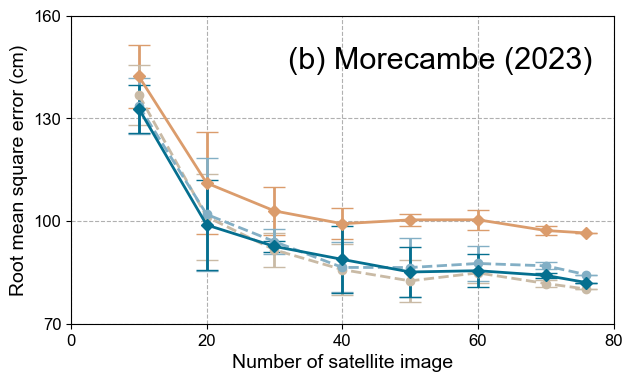

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# 示例数据（可以替换为你的实际数据）
x = np.array([10, 20, 30, 40, 50, 60, 70, 76])# 比如距离或序号，共30个点

fig, ax = plt.subplots(figsize=(7, 4))


color_list = ["#DB9C6C","#C9BAA5", "#83AFC5", "#056F8F"]
# color_list = ["#F0AD30","#34699A", "#58A0C8", "#113F67"]
# 绘制误差棒图（上下误差相等）
ax.errorbar(x, mean_1_list, yerr=std_1_list, fmt='D-', color=color_list[0], ecolor=color_list[0], capsize=8, elinewidth=2, linewidth=2)
ax.errorbar(x, mean_2_list, yerr=std_2_list, fmt='o--', color=color_list[1], ecolor=color_list[1], capsize=8, linewidth=2)
ax.errorbar(x, mean_3_list, yerr=std_3_list, fmt='o--', color=color_list[2], ecolor=color_list[2], capsize=8, elinewidth=2, linewidth=2)
ax.errorbar(x, mean_4_list, yerr=std_4_list, fmt='D-', color=color_list[3], ecolor=color_list[3], capsize=8, linewidth=2)

# 添加零线（更粗）
ax.axhline(y=0, linestyle='-', color='gray', linewidth=10, alpha=0.3)


ax.plot([], [], 'D-',  color=color_list[0], markeredgecolor=color_list[0], label='NAEF only')
ax.plot([], [], 'o--',  color=color_list[1], markeredgecolor=color_list[1], label='NAEF+NDWImean')
ax.plot([], [], 'o--',  color=color_list[2], markeredgecolor=color_list[2], label='NAEF+NDWImean+MNDWImean')
ax.plot([], [], 'D-',  color=color_list[3], markeredgecolor=color_list[3], label='All elevation proxies')


# ax.errorbar([], [], yerr=[[0.5], [0.5]], fmt='', ecolor='black', capsize=5, label='All_bands ±std.')
# ax.errorbar([], [], yerr=[[0.1], [0.1]], fmt='', ecolor='black', capsize=5, label='Frequence ±std.')
# ax.legend(frameon=True, fontsize = 12)

ax.grid(axis='x', linestyle='--', alpha=1)
ax.grid(axis='y', linestyle='--', alpha=1)
ax.grid(True)

ax.text(0.40, 0.90, '(b) Morecambe (2023) ', transform=ax.transAxes, fontsize=22,
        verticalalignment='top',)

# 标签与样式
ax.tick_params(axis='both', labelsize=12)
ax.set_ylabel('Root mean square error (cm)', fontsize=14)
#ax.set_ylabel('Mean absolute error (cm)', fontsize=14)
ax.set_xlabel('Number of satellite image', fontsize=14)
ax.set_ylim(70, 160)
plt.xlim(0, 80)
plt.yticks(np.arange(70, 161, 30))
plt.xticks(np.arange(0, 81, 20))
# ax.set_ylim(10, 60)
# ax.set_xlim(0, 100)
# plt.tight_layout()
plt.show()

In [86]:
points = gpd.read_file('G:\ICESat-2\Discussion51_new\Validation_point_Thames_new7.shp')
points.columns

Index(['Refer_dem', 'B1_10_2', 'B2_10_2', 'B3_10_2', 'B4_10_2', 'B1_20_2',
       'B2_20_2', 'B3_20_2', 'B4_20_2', 'B1_30_2',
       ...
       'B4_20_5', 'B4_30_5', 'B4_40_5', 'B4_50_5', 'B4_60_5', 'B4_70_5',
       'B4_80_5', 'B4_90_5', 'B4_100_5', 'geometry'],
      dtype='object', length=222)

In [7]:
num = [10, 20, 30, 40, 50 ,60, 70, 80, 90, 100]
No = [2, 3, 4,  7, 9]
points = gpd.read_file('G:\ICESat-2\Discussion51_new\Validation_point_Thames_new7.shp')
# 四个 band
RMSE_1_list, MAD_1_list = compute_metrics(points, 'B1', num, No)
RMSE_2_list, MAD_2_list = compute_metrics(points, 'B2', num, No)
RMSE_3_list, MAD_3_list = compute_metrics(points, 'B3', num, No)
RMSE_4_list, MAD_4_list = compute_metrics(points, 'B4', num, No)

mean_1_list,mean_2_list,mean_3_list, mean_4_list = [], [], [], []
std_1_list, std_2_list, std_3_list, std_4_list = [], [], [], []
N  = len(No)

for i in range(1, len(num)+1):
    
    ii = i*N-N
    mean1 = np.array(RMSE_1_list[ii:ii+5]).mean()
    std1 = np.array(RMSE_1_list[ii:ii+5]).std()
    mean_1_list.append(mean1*100)
    std_1_list.append(std1*100)
    
    mean2 = np.array(RMSE_2_list[ii:ii+5]).mean()
    std2 = np.array(RMSE_2_list[ii:ii+5]).std()
    mean_2_list.append(mean2*100)
    std_2_list.append(std2*100)    
    
    mean3 = np.array(RMSE_3_list[ii:ii+5]).mean()
    std3 = np.array(RMSE_3_list[ii:ii+5]).std()
    mean_3_list.append(mean3*100)
    std_3_list.append(std3*100)
    
    mean4 = np.array(RMSE_4_list[ii:ii+5]).mean()
    std4 = np.array(RMSE_4_list[ii:ii+5]).std()  
    mean_4_list.append(mean4*100)
    std_4_list.append(std4*100) 

In [18]:
# print(np.mean(mean_2_list))
# np.mean(mean_1_list)
mean_2_list
RMSE_4_list[0:10]
std_4_list.append(std4*100) 
std_4_list


[5.097011294189396,
 5.473372840550813,
 3.353074541514457,
 1.459964995104182,
 1.9696778070040586,
 1.6086450139257702,
 1.0864604326539984,
 1.2456390828220307,
 0.7593042674971661,
 0.3602261323461085,
 0.3602261323461085,
 0.3602261323461085]

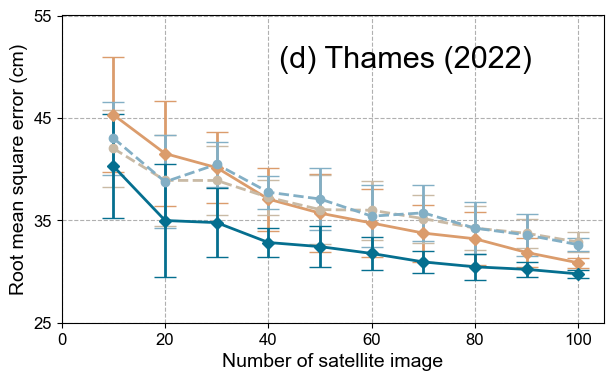

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'

# 示例数据（可以替换为你的实际数据）
x = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90 ,100])# 比如距离或序号，共30个点

fig, ax = plt.subplots(figsize=(7, 4))


color_list = ["#DB9C6C","#C9BAA5", "#83AFC5", "#056F8F"]
# color_list = ["#F0AD30","#34699A", "#58A0C8", "#113F67"]
# 绘制误差棒图（上下误差相等）
ax.errorbar(x, mean_1_list, yerr=std_1_list, fmt='D-', color=color_list[0], ecolor=color_list[0], capsize=8, elinewidth=2, linewidth=2)
ax.errorbar(x, mean_2_list, yerr=std_2_list, fmt='o--', color=color_list[1], ecolor=color_list[1], capsize=8, linewidth=2)
ax.errorbar(x, mean_3_list, yerr=std_3_list, fmt='o--', color=color_list[2], ecolor=color_list[2], capsize=8, elinewidth=2, linewidth=2)
ax.errorbar(x, mean_4_list, yerr=std_4_list, fmt='D-', color=color_list[3], ecolor=color_list[3], capsize=8, linewidth=2)

# 添加零线（更粗）
ax.axhline(y=0, linestyle='-', color='gray', linewidth=10, alpha=0.3)


ax.plot([], [], 'D-',  color=color_list[0], markeredgecolor=color_list[0], label='NAEF only')
ax.plot([], [], 'o--',  color=color_list[1], markeredgecolor=color_list[1], label='NAEF+NDWImean')
ax.plot([], [], 'o--',  color=color_list[2], markeredgecolor=color_list[2], label='NAEF+NDWImean+MNDWImean')
ax.plot([], [], 'D-',  color=color_list[3], markeredgecolor=color_list[3], label='All elevation proxies')


# ax.errorbar([], [], yerr=[[0.5], [0.5]], fmt='', ecolor='black', capsize=5, label='All_bands ±std.')
# ax.errorbar([], [], yerr=[[0.1], [0.1]], fmt='', ecolor='black', capsize=5, label='Frequence ±std.')
# ax.legend(frameon=True, fontsize = 12)

ax.text(0.40, 0.90, '(d) Thames (2022) ', transform=ax.transAxes, fontsize=22,
        verticalalignment='top',)
ax.grid(axis='x', linestyle='--', alpha=1)
ax.grid(axis='y', linestyle='--', alpha=1)
ax.grid(True)

# 标签与样式
ax.tick_params(axis='both', labelsize=12)
ax.set_ylabel('Root mean square error (cm)', fontsize=14)
#ax.set_ylabel('Mean absolute error (cm)', fontsize=14)
ax.set_xlabel('Number of satellite image', fontsize=14)
ax.set_ylim(25, 55.1)
plt.xlim(0, 105)
plt.yticks(np.arange(25, 55.1, 10))
plt.xticks(np.arange(0, 101, 20))
# ax.set_ylim(10, 60)
# ax.set_xlim(0, 100)
# plt.tight_layout()
plt.show()

In [10]:
print('Wash ')
print(np.mean(mean_1_list))
print(np.mean(mean_2_list))
print(np.mean(mean_3_list))
print(np.mean(mean_4_list))

Wash 
101.03234544377213
84.68770655942676
83.71713054685058
86.96875793788932


In [20]:
points.columns

Index(['Refer_dem', 'B1_10_0', 'B2_10_0', 'B3_10_0', 'B4_10_0', 'B1_20_0',
       'B2_20_0', 'B3_20_0', 'B4_20_0', 'B1_30_0',
       ...
       'B4_50_4', 'B1_60_4', 'B2_60_4', 'B3_60_4', 'B4_60_4', 'B1_70_4',
       'B2_70_4', 'B3_70_4', 'B4_70_4', 'geometry'],
      dtype='object', length=142)

R² = 0.793, MAE = 0.584, MSB = 0.321, RMSE = 0.802, N = 10046


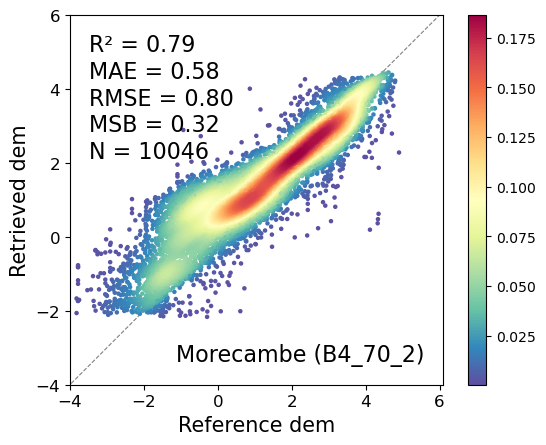

R² = 0.808, MAE = 0.562, MSB = 0.293, RMSE = 0.772, N = 10046


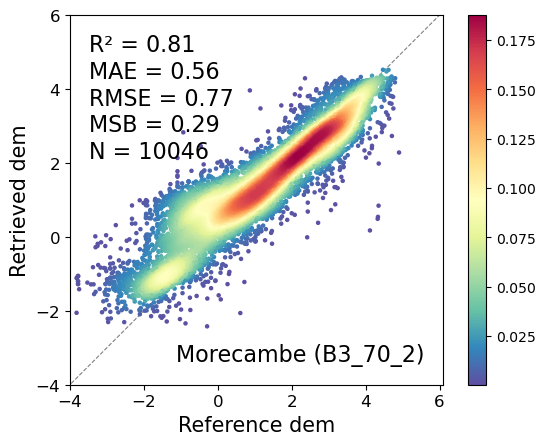

R² = 0.794, MAE = 0.578, MSB = 0.311, RMSE = 0.800, N = 10046


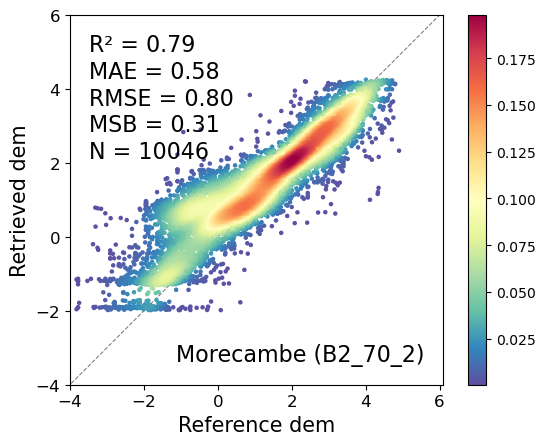

R² = 0.733, MAE = 0.708, MSB = 0.356, RMSE = 0.911, N = 10046


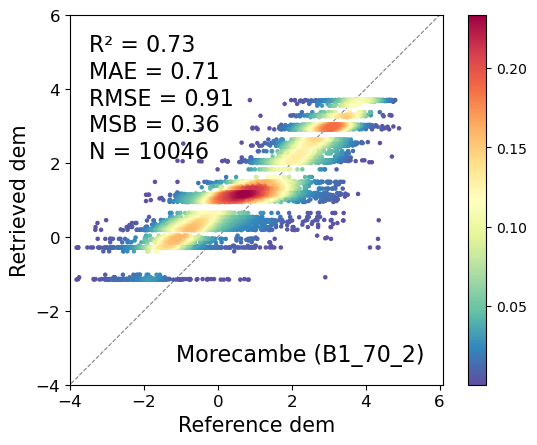

In [25]:
import matplotlib.pyplot as plt
location2 = 'Morecambe'
target_name_list = ['B4_70_2', 'B3_70_2', 'B2_70_2', 'B1_70_2']
for target_name in target_name_list:
    
    z = points[['Refer_dem', target_name]]
    mask = (z[target_name] != 0) | (z['Refer_dem'] !=6) | (z['Refer_dem'] != -999)
    z = z[mask]
    z = z[z!=-999]
    z = z[z!=6]
    z = z[z!=0]
    z = z.dropna()
    x = np.array(z['Refer_dem']) #y_true
    y = np.array(z[target_name]) # y_pred
    xy_lim_range = [-3, 5]
        # R, _ = pearsonr(y, x)
    R2 = r2_score(x, y) #r2_score(y_true, y_pred)
    MAE = np.mean(np.abs(y-x))
    MSB = np.mean((y-x))
    RMSE = np.sqrt(np.mean((y-x)**2))
    num = int(len(x))

    print(f"R² = {R2:.3f}, MAE = {MAE:.3f}, MSB = {MSB:.3f}, RMSE = {RMSE:.3f}, N = {num}")
        
    xy = np.vstack([x,y])  #  将两个维度的数据叠加
    z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

        # Sort the points by density, so that the densest points are plotted last
    idx = z.argsort()
    x_sorted, y_sorted, z_sorted = x[idx], y[idx], z[idx]

    fig, ax = plt.subplots()
    textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f} \nMSB = {MSB:.2f}\nN = {num}"
    name = f'{location2} ({target_name})'
    ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 16, verticalalignment = 'top')
    ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

    ax.set_xlabel('Reference dem', fontsize = 15)
    ax.set_ylabel('Retrieved dem', fontsize = 15)
    ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)

    sc = plt.scatter(x_sorted, y_sorted, c=z_sorted, s=5, cmap='Spectral_r', zorder=2)
    cbar = plt.colorbar(sc)

        # plt.scatter(x, y,c=z, s=2,cmap='Spectral_r') # c表示标记的颜色
        # plt.colorbar()

    ax.set_xlim(-4, 6.1)
    ax.set_ylim(-4, 6)

    # 设置一致的刻度间隔（例如每 1 单位一个刻度）
    tick_interval = 2
    ticks = np.arange(-4, 4.1 + tick_interval, tick_interval)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)

    # 设置等比例显示
    ax.set_aspect('equal')

    ax.tick_params(axis='both', labelsize=12)
    # output_path = f'G:\ICESat-2\Discussion5_1_new\plot/{location2}_{target_name}.png'
    # plt.savefig(output_path, dpi=300, bbox_inches='tight')  # 保存图像
    plt.show()
    plt.close()